import csv and check the head of the dataframe 

In [14]:
import matplotlib.pyplot as plt 
import pandas as pd 

df = pd.read_csv("/Users/hayansaab/Desktop/research/Sparkov_Data_Generation/output_data/transactions.csv", sep= '|')
print(df.head())



           ssn            cc_num    first   last gender   race  \
0  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
1  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
2  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
3  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
4  082-30-1655  5332871012269166  Matthew  Mejia      M  white   

                      street          city state    zip  ...   unix_time  \
0  7525 Clark Grove Apt. 928  Newport News    VA  23603  ...  1767345928   
1  7525 Clark Grove Apt. 928  Newport News    VA  23603  ...  1767751202   
2  7525 Clark Grove Apt. 928  Newport News    VA  23603  ...  1767783881   
3  7525 Clark Grove Apt. 928  Newport News    VA  23603  ...  1768147920   
4  7525 Clark Grove Apt. 928  Newport News    VA  23603  ...  1768237814   

      category    amt is_fraud                merchant  merch_lat merch_long  \
0  food_dining  93.00        0                  Arby's  37.554566 

In [15]:
print(df.shape)

(891174, 33)


In [16]:
pd.set_option('display.max_columns', None)
print(df.head())

           ssn            cc_num    first   last gender   race  \
0  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
1  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
2  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
3  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
4  082-30-1655  5332871012269166  Matthew  Mejia      M  white   

                      street          city state    zip      lat     long  \
0  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
1  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
2  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
3  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
4  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   

   city_pop        job         dob      acct_num                      profile  \
0    179275  Professor  1971-08-05  269419548116  adults_50

In [17]:
print(df['trans_date'].dtype)


object


In [18]:
df['trans_date'] = pd.to_datetime(df['trans_date'])

           ssn            cc_num    first   last gender   race  \
0  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
1  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
2  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
3  082-30-1655  5332871012269166  Matthew  Mejia      M  white   
4  082-30-1655  5332871012269166  Matthew  Mejia      M  white   

                      street          city state    zip      lat     long  \
0  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
1  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
2  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
3  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
4  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   

   city_pop        job         dob      acct_num income_band      education  \
0    179275  Professor  1971-08-05  269419548116       100k+ 

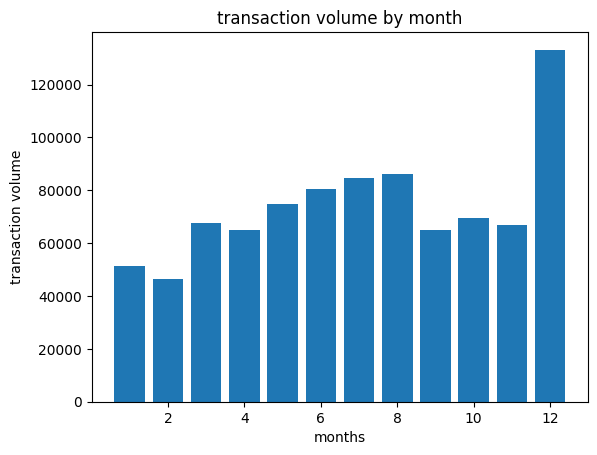

In [19]:
new = df.drop(columns = ['profile', 'trans_num',])
print(new.head())
months = new['trans_date'].dt.month
months_matrix = months.value_counts().sort_index()

plt.bar(months_matrix.index, months_matrix.values)
plt.xlabel('months')
plt.ylabel('transaction volume')
plt.title("transaction volume by month")
plt.show()

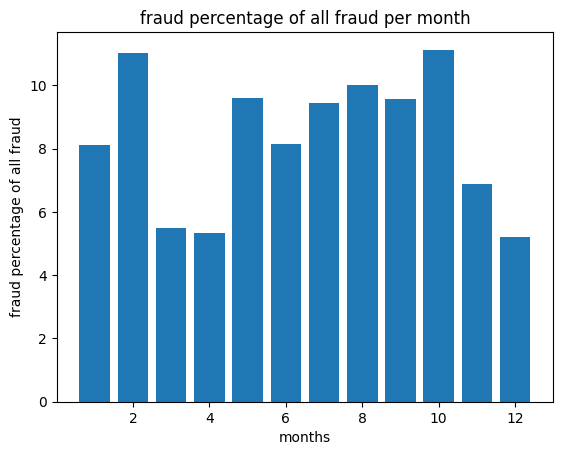

In [20]:
total_fraud = (new['is_fraud']==1).sum()
fraud_df = new.loc[new['is_fraud'] == 1, 'trans_date']
fraud_counts = fraud_df.dt.month.value_counts().sort_index()
plt.bar(fraud_counts.index, fraud_counts.values/total_fraud * 100)

plt.xlabel('months')
plt.ylabel('fraud percentage of all fraud')
plt.title('fraud percentage of all fraud per month')
plt.show()

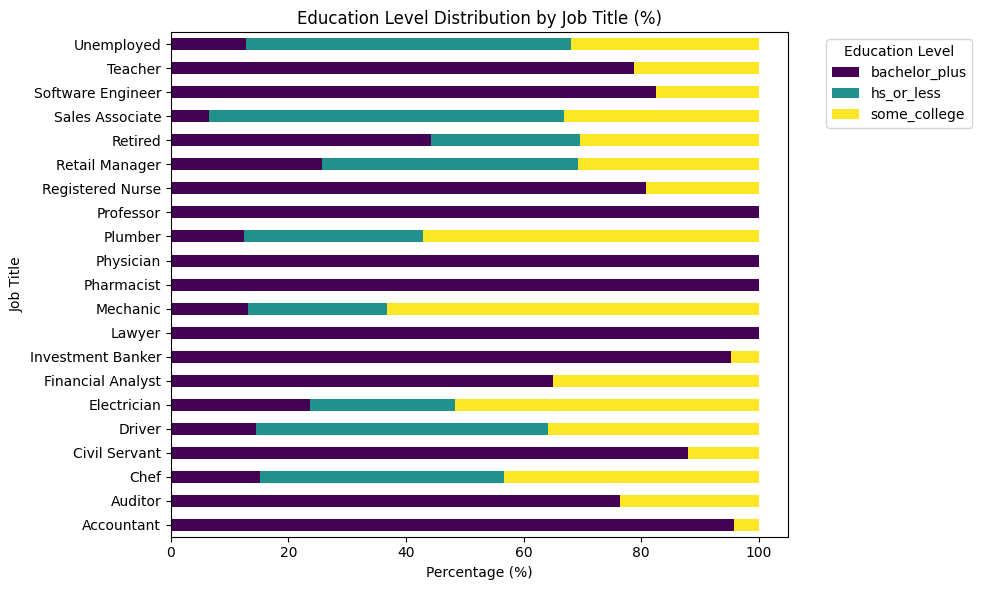

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create cross-tabulation (normalized to percentages per job)
job_edu = pd.crosstab(new['job'], new['education'], normalize='index') * 100

# 2. Plot 100% Stacked Bar Chart
job_edu.plot(kind='barh', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Education Level Distribution by Job Title (%)')
plt.xlabel('Percentage (%)')
plt.ylabel('Job Title')
plt.legend(title='Education Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [22]:
job_distribution = new['job'].value_counts(normalize = True)* 100 
print (job_distribution)

job
Unemployed           20.832520
Retired              19.989250
Plumber               4.961321
Driver                4.790647
Sales Associate       4.466917
Retail Manager        4.142850
Chef                  3.768288
Electrician           3.652710
Investment Banker     3.400907
Civil Servant         3.400234
Professor             3.274894
Mechanic              3.113309
Physician             2.911440
Pharmacist            2.873401
Teacher               2.498951
Software Engineer     2.333888
Auditor               2.255340
Registered Nurse      2.129999
Accountant            1.922184
Lawyer                1.762731
Financial Analyst     1.518222
Name: proportion, dtype: float64


In [23]:
education_distribution = new['education'].value_counts(normalize = True)* 100 
print (education_distribution)

education
bachelor_plus    43.238245
some_college     28.572871
hs_or_less       28.188883
Name: proportion, dtype: float64


<Axes: title={'center': 'Education distribution'}, ylabel='proportion'>

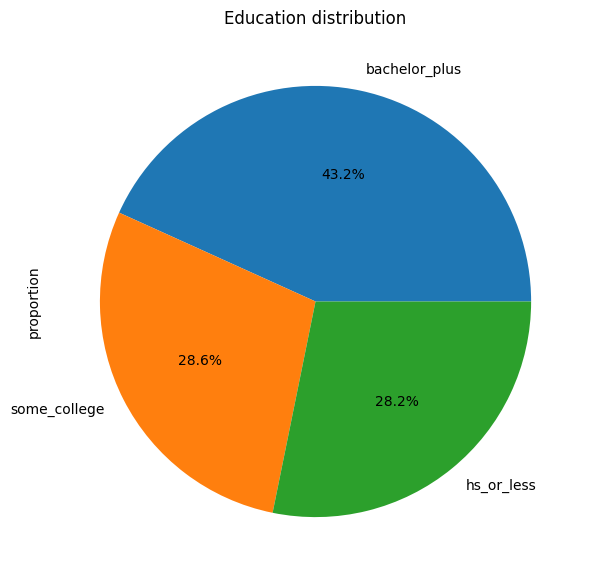

In [24]:
education_distribution.plot(kind = 'pie', autopct = '%1.1f%%', figsize  = (7,7), title = 'Education distribution')


<Axes: title={'center': 'Job distribution'}, ylabel='proportion'>

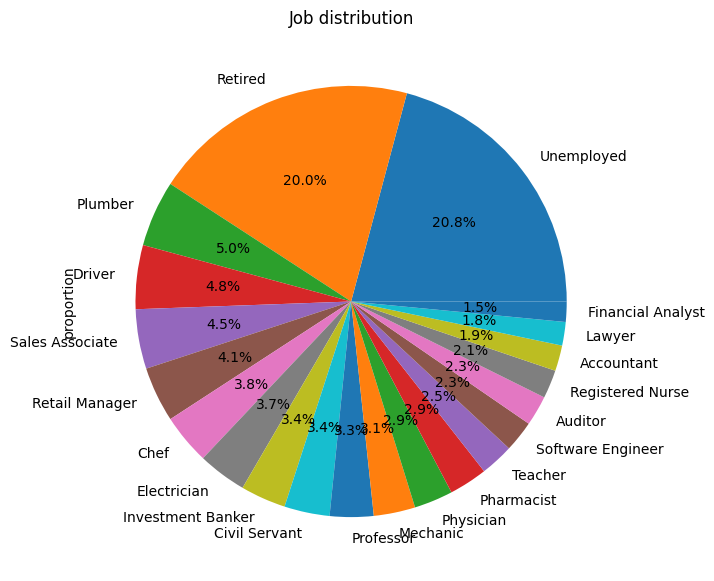

In [25]:
job_distribution.plot(kind = 'pie', autopct = '%1.1f%%', figsize  = (7,7), title = 'Job distribution')

In [ ]:
import seaborn as sns


### Attribute Correlation & Heatmap Analysis

The following code performs normalization and correlation analysis across major numeric, derived, and encoded attributes in the dataset.

1. **Derived Attributes**: Calculates customer `age`, transaction `trans_hour`, and customer-to-merchant `distance_km`.
2. **Categorical Encoding**: Maps ordinal and binary attributes (`gender`, `income_band`, `education`, `marital_status`, `merchant_size`) to numeric codes.
3. **Robust Normalization**: Calculates **Spearman Rank Correlation** to normalize pairwise relationships into `[-1.0, 1.0]`, resilient to non-linearities and extreme transaction/fraud outliers.


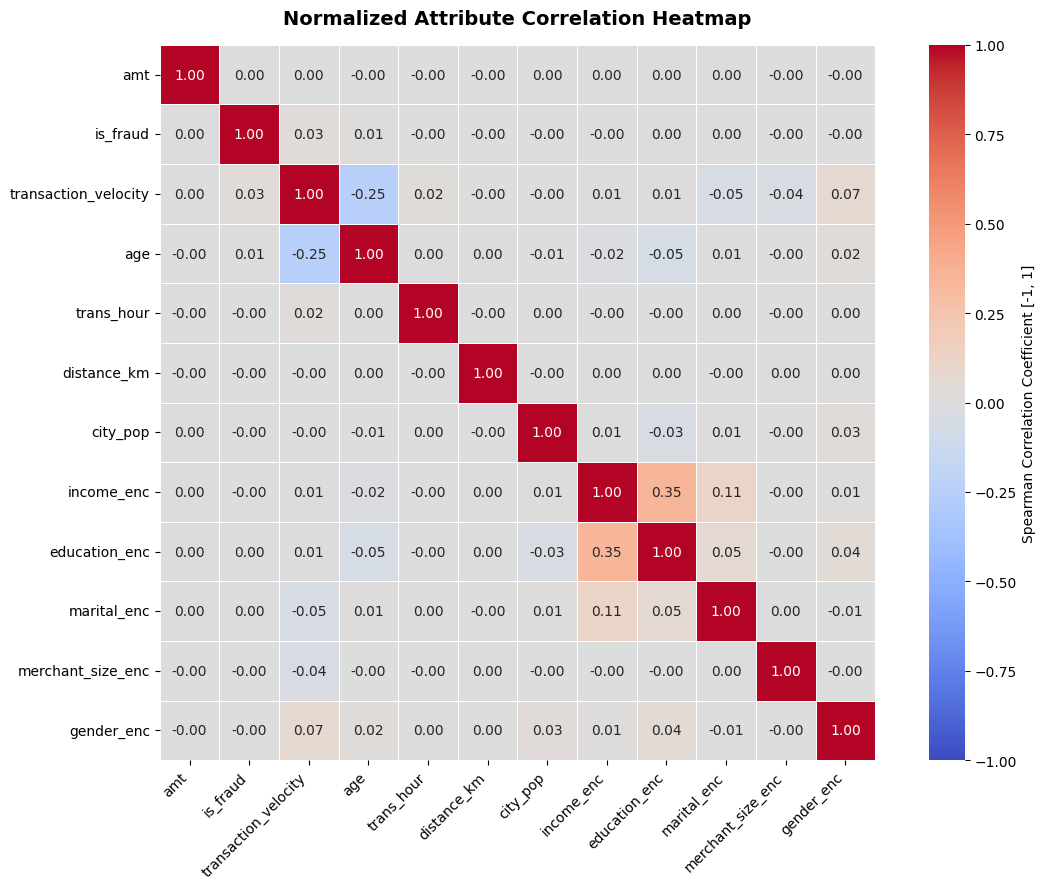

In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Feature Engineering & Derived Attributes
df_attr = df.copy()
df_attr["age"] = (pd.to_datetime(df_attr["trans_date"]) - pd.to_datetime(df_attr["dob"])).dt.days // 365
df_attr["trans_hour"] = pd.to_datetime(df_attr["trans_time"], format="%H:%M:%S").dt.hour
df_attr["distance_km"] = np.sqrt(
    (df_attr["lat"] - df_attr["merch_lat"])**2 + 
    (df_attr["long"] - df_attr["merch_long"])**2
) * 111  # Approximate distance in km

# 2. Categorical Encoding (Matching Dataset Categories)
gender_map = {"M": 0, "F": 1}
income_map = {"<50k": 0, "50-100k": 1, "100k+": 2}
edu_map = {"hs_or_less": 0, "some_college": 1, "bachelor_plus": 2}
marital_map = {"never_married": 0, "formerly_married": 1, "married": 2}
size_map = {"small": 0, "medium": 1, "large": 2}

df_attr["gender_enc"] = df_attr["gender"].map(gender_map)
df_attr["income_enc"] = df_attr["income_band"].map(income_map)
df_attr["education_enc"] = df_attr["education"].map(edu_map)
df_attr["marital_enc"] = df_attr["marital_status"].map(marital_map)
df_attr["merchant_size_enc"] = df_attr["merchant_size"].map(size_map)

# Selected Numerical & Encoded Features
features = [
    "amt", "is_fraud", "transaction_velocity", "age", "trans_hour", 
    "distance_km", "city_pop", "income_enc", "education_enc", 
    "marital_enc", "merchant_size_enc", "gender_enc"
]

corr_subset = df_attr[features].dropna()

# 3. Compute Spearman Rank Correlation (Normalized [-1, 1])
corr_matrix = corr_subset.corr(method="spearman")

# 4. Plot Normalized Attribute Heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Spearman Correlation Coefficient [-1, 1]"}
)

plt.title("Normalized Attribute Correlation Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


In [27]:
categories_marital = new['marital_status'].unique()
print(categories_marital)

['married' 'never_married' 'formerly_married']


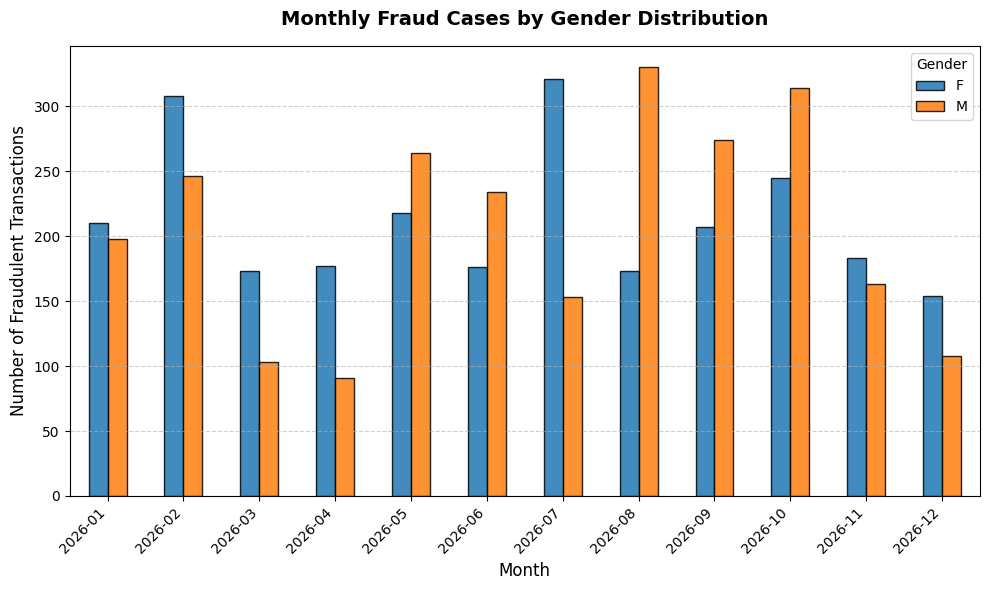

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# Reload df if 'trans_date' was dropped in a previous cell
if 'df' not in locals() or 'trans_date' not in df.columns:
  df = pd.read_csv(
      '/Users/hayansaab/Desktop/research/Sparkov_Data_Generation/output_data/transactions.csv',
      sep='|',
  )

# 1. Ensure trans_date is converted to datetime format
df['trans_date'] = pd.to_datetime(df['trans_date'])

# 2. Filter dataset for fraudulent transactions only
fraud_df = df[df['is_fraud'] == 1].copy()

# 3. Extract year and month (e.g., '2026-01', '2026-02')
fraud_df['month'] = fraud_df['trans_date'].dt.strftime('%Y-%m')

# 4. Group by month and gender
monthly_gender_fraud = fraud_df.groupby(['month', 'gender']).size().unstack(
    fill_value=0
)

# 5. Plot bar chart
ax = monthly_gender_fraud.plot(
    kind='bar', figsize=(10, 6), edgecolor='black', alpha=0.85
)

plt.title(
    'Monthly Fraud Cases by Gender Distribution',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Fraudulent Transactions', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend(title='Gender', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


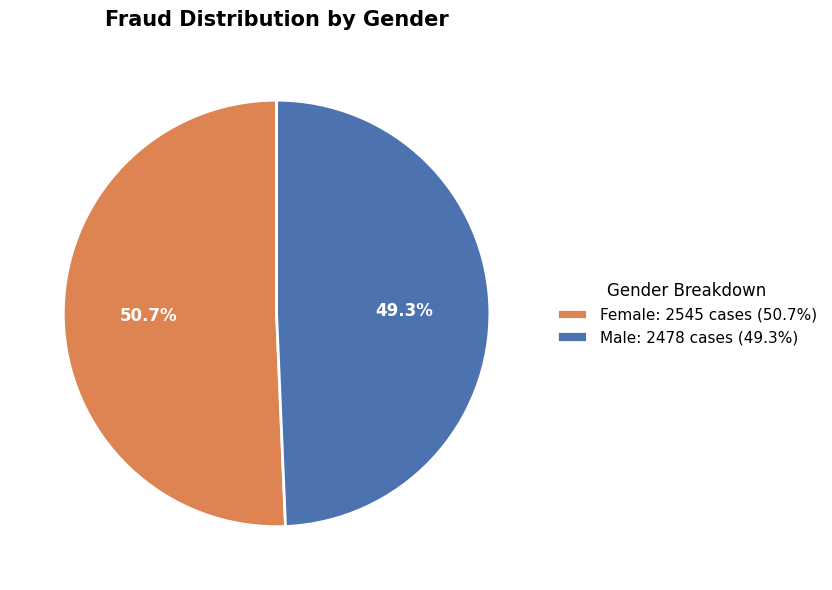

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# Reload df if needed
if 'df' not in locals() or 'is_fraud' not in df.columns:
  df = pd.read_csv(
      '/Users/hayansaab/Desktop/research/Sparkov_Data_Generation/output_data/transactions.csv',
      sep='|',
  )

# 1. Filter dataset for fraud
fraud_df = df[df['is_fraud'] == 1]
gender_counts = fraud_df['gender'].value_counts()

# 2. Modern Palette & Mapping
color_map = {'M': '#4C72B0', 'F': '#DD8452'}  # Modern muted blue & warm coral
label_map = {'M': 'Male', 'F': 'Female'}

labels = [label_map[g] for g in gender_counts.index]
colors = [color_map[g] for g in gender_counts.index]
total_fraud = sum(gender_counts)

# 3. Plotting
fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    gender_counts,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.6,
    textprops={'fontsize': 12, 'weight': 'bold', 'color': 'white'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},  # Clean thin white border
)

# 4. Add clean Side Legend with Case Counts & Percentages
legend_labels = [
    f'{label}: {count} cases ({count/total_fraud*100:.1f}%)'
    for label, count in zip(labels, gender_counts)
]

ax.legend(
    wedges,
    legend_labels,
    title='Gender Breakdown',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    fontsize=11,
    title_fontsize=12,
    frameon=False,
)

plt.title('Fraud Distribution by Gender', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


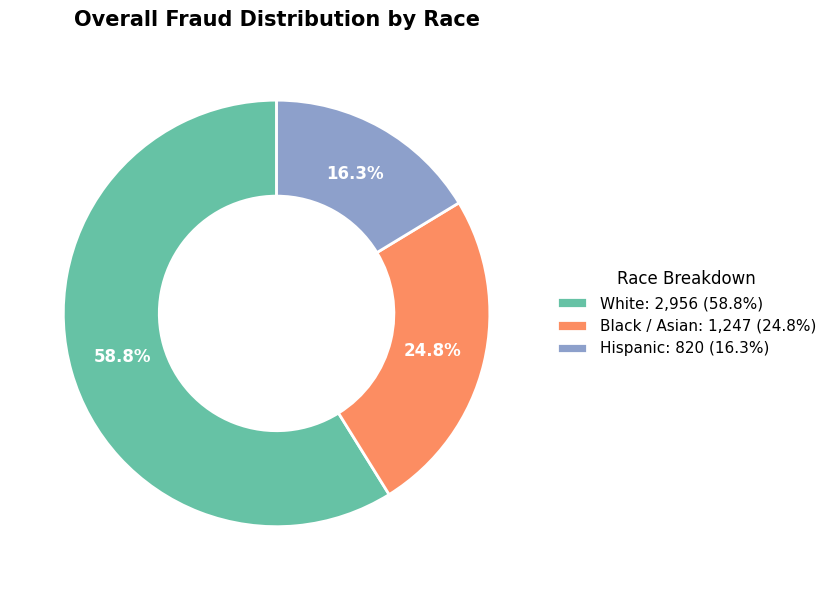

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

# Load df if needed
if 'df' not in locals() or 'is_fraud' not in df.columns or 'race' not in df.columns:
  df = pd.read_csv(
      './Sparkov_Data_Generation/output_data/transactions.csv', sep='|'
  )

# 1. Filter for fraud transactions
fraud_df = df[df['is_fraud'] == 1]
race_counts = fraud_df['race'].value_counts()

# 2. Map labels & colors
race_label_map = {
    'white': 'White',
    'hispanic': 'Hispanic',
    'black_asian': 'Black / Asian',
}
labels = [race_label_map.get(r, r) for r in race_counts.index]
total_fraud = sum(race_counts)
colors = ['#66c2a5', '#fc8d62', '#8da0cb']

# 3. Plot Donut Chart
fig, ax = plt.subplots(figsize=(8, 6))
wedges, texts, autotexts = ax.pie(
    race_counts,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors[: len(race_counts)],
    pctdistance=0.75,
    textprops={'fontsize': 12, 'weight': 'bold', 'color': 'white'},
    wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2},
)

# 4. Side Legend with Counts and Percentages
legend_labels = [
    f'{label}: {count:,} ({count/total_fraud*100:.1f}%)'
    for label, count in zip(labels, race_counts)
]
ax.legend(
    wedges,
    legend_labels,
    title='Race Breakdown',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    fontsize=11,
    title_fontsize=12,
    frameon=False,
)

plt.title(
    'Overall Fraud Distribution by Race', fontsize=15, fontweight='bold', pad=15
)
plt.tight_layout()
plt.show()


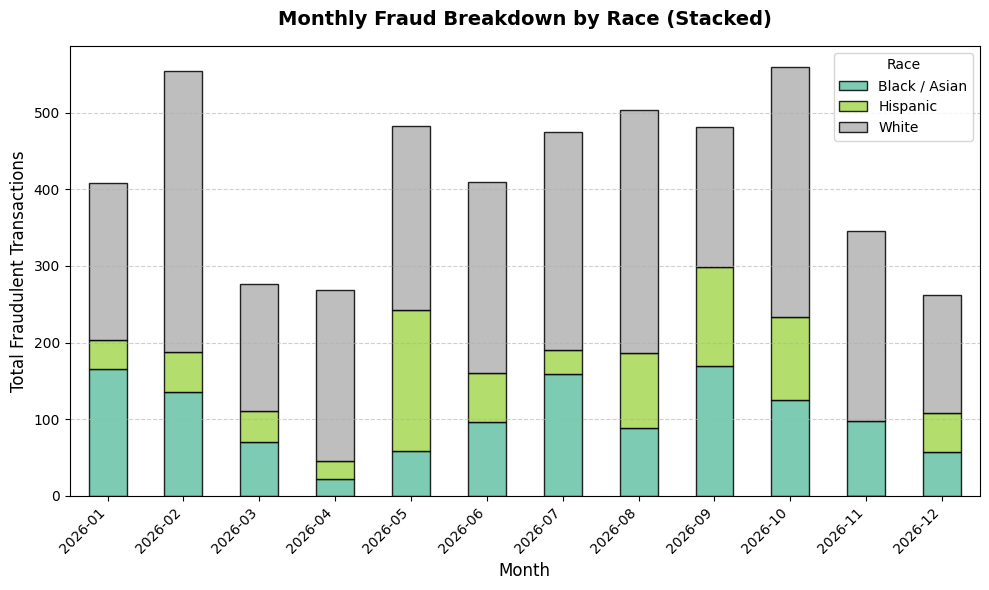

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

# Load df if needed
if (
    'df' not in locals()
    or 'is_fraud' not in df.columns
    or 'race' not in df.columns
):
  df = pd.read_csv(
      './Sparkov_Data_Generation/output_data/transactions.csv', sep='|'
  )

# 1. Filter for fraud transactions only
fraud_df = df[df['is_fraud'] == 1].copy()
fraud_df['trans_date'] = pd.to_datetime(fraud_df['trans_date'])
fraud_df['month'] = fraud_df['trans_date'].dt.strftime('%Y-%m')

# 2. Map race labels
race_label_map = {
    'white': 'White',
    'hispanic': 'Hispanic',
    'black_asian': 'Black / Asian',
}

# 3. Group by month and race
monthly_race_fraud = fraud_df.groupby(['month', 'race']).size().unstack(
    fill_value=0
)
monthly_race_fraud = monthly_race_fraud.rename(columns=race_label_map)

# 4. Plot STACKED Bar Chart (Height = Exact Monthly Total Fraud)
fig, ax = plt.subplots(figsize=(10, 6))
monthly_race_fraud.plot(
    kind='bar', stacked=True, ax=ax, colormap='Set2', edgecolor='black', alpha=0.85
)

plt.title(
    'Monthly Fraud Breakdown by Race (Stacked)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Fraudulent Transactions', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend(title='Race', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
